In [ ]:
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sb
import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.tsaplots import plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import  mean_squared_error, mean_absolute_error



df = pd.read_csv('data/train.csv', sep=',')
df_test = pd.read_csv('data/test.csv', sep = ',')



Text(0, 0.5, 'Prodato(u 1000)')

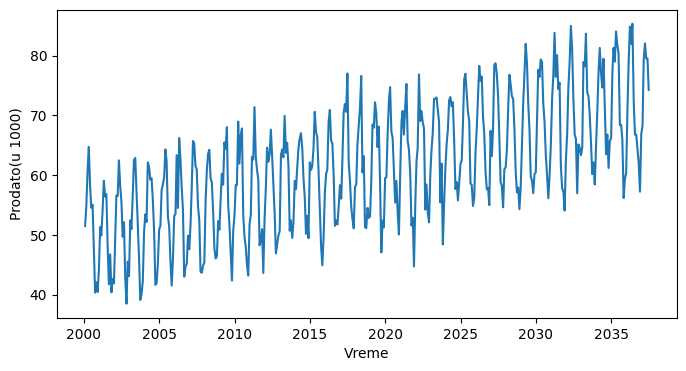

In [ ]:

df['Month'] = pd.to_datetime(df['Time'])
df = df.set_index('Month')

df_test['Month'] = pd.to_datetime(df_test['Time'])
df_test = df_test.set_index('Month')

df = df.asfreq('ME')
df_test = df_test.asfreq('ME')

matplotlib.rcParams['figure.figsize'] = (8, 4)
x, y = df.index, df['Value']
plt.plot(x, y)
plt.xlabel('Vreme')
plt.ylabel('Prodato(u 1000)')





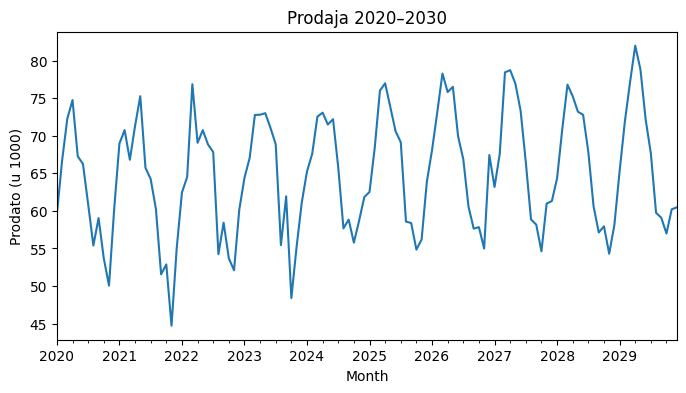

In [ ]:
df_subset = df.loc["2020-01-31":"2029-12-31"]

df_subset["Value"].plot(title="Prodaja 2020–2030")
plt.ylabel("Prodato (u 1000)")
plt.show()

Na grafu primećujem globalni uzlazni trend. Bazirano na znanju iz zivota, ako je neki proizvod dobar on ce se vremenom prodavati sve bolje i bolje( prilagodjeno naravno za stanje marketa), kao i analizom grafa gde vidmo da se prodaja povecava i smanjuje sezonski ali da ne zavisi od globalnog trenda, zakljucujem da je u pitanju aditivni model. Takodje na manjoj sekciji vidimo da imamo trend ali ne i oscilacije prodaje koje ga prate.Primenio sam bio i logaritam na podatke ali se graf ne promeni uopste.

### STL dekompozicija

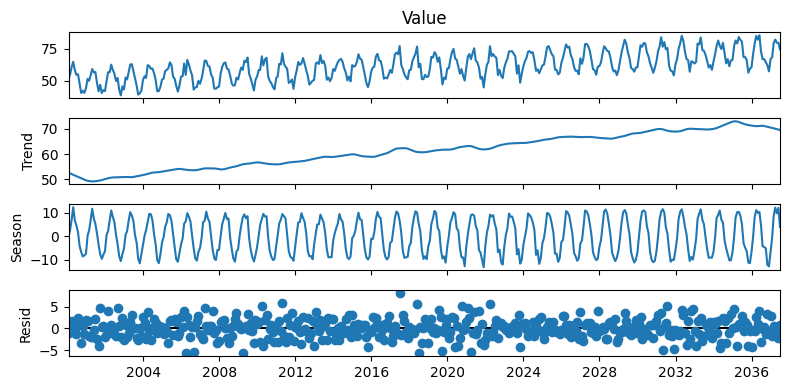

In [ ]:

stl = STL(df['Value']).fit()
stl_test = STL(df_test['Value']).fit()
df_test['stacionarni'] = df_test['Value'] - stl_test.trend

stl.plot()
plt.show()
trend, seasonal, resid = stl.trend, stl.seasonal, stl.resid

Potvrdjena prethodna tvrdnja o uzlaznom trendu. Takodje vidi se sezonalnost i njen period je 12 meseci.

### Stacionarnost

In [ ]:
def proveri_stacionarnost(Podaci):
    adf_value = adfuller(Podaci)[0]
    p_value = adfuller(Podaci)[1]
    print(f'{adf_value=:.2f}, {p_value}')

    if p_value <= 0.05: print('postoji stacionarnost')
    else: print('ne postoji stacionarnost')
proveri_stacionarnost(df['Value'])

adf_value=-0.82, 0.8125192295033581
ne postoji stacionarnost


Vidimo preko testa da ne postoji stacionarnost u podacima, analiom grafa vidimo da zasigurno postoji problem srednje vrednosti pa cu to prvo da resim.

adf_value=-15.12, 7.573624978531749e-28
postoji stacionarnost


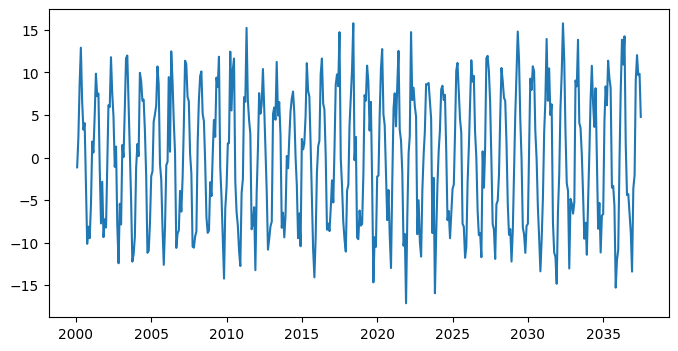

In [ ]:
stacionarni = df['Value'] - trend
proveri_stacionarnost(stacionarni)
plt.plot(stacionarni)

df['stacionarni'] = stacionarni

Uklanjanjem trenda, doveli smo seriju u stanje stacionarnosti.

### Odredjivanje autokorelacije

In [ ]:
result1 = acorr_ljungbox(df['stacionarni'], lags=15, return_df=True)

| Lag | lb_stat     | lb_pvalue       |
|-----|-------------|-----------------|
| 1   | 245.394708  | 2.621027e-55    |
| 2   | 326.175993  | 1.485194e-71    |
| 3   | 326.212524  | 2.107978e-70    |
| 4   | 418.379576  | 2.969210e-89    |
| 5   | 673.232469  | 3.009033e-143   |
| 6   | 1008.853437 | 1.087797e-214   |
| 7   | 1261.702510 | 3.197009e-268   |
| 8   | 1348.334899 | 8.373033e-286   |
| 9   | 1348.335090 | 1.122162e-284   |
| 10  | 1430.047415 | 3.225915e-301   |
| 11  | 1686.120754 | 0.000000e+00    |
| 12  | 2022.447238 | 0.000000e+00    |
| 13  | 2267.777809 | 0.000000e+00    |
| 14  | 2350.415459 | 0.000000e+00    |
| 15  | 2350.419575 | 0.000000e+00    |

Vidimo da imamo jaku autokorelaciju sa lagovima do 10.  

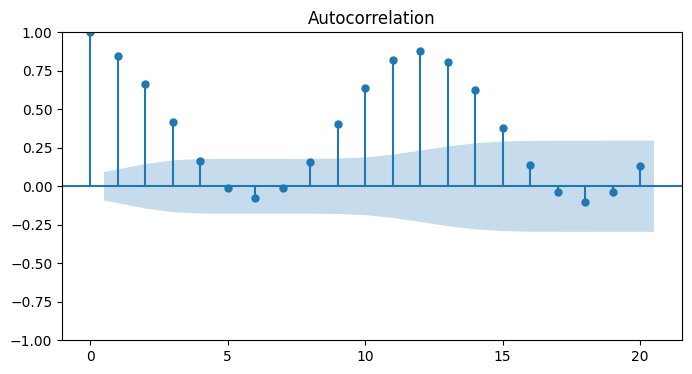

In [ ]:
plot_acf(df['Value'], lags=20)
plt.show()

Vidimo da za k =  1,2,3,9,10,11,12,13,14 postoji znacajna autokorelacija. Takodje vidimo da postoji obrazac, kao sinus, sto nam pokazuje da u podacima postoji sezonska komponenta koja je perioda  12 meseci.

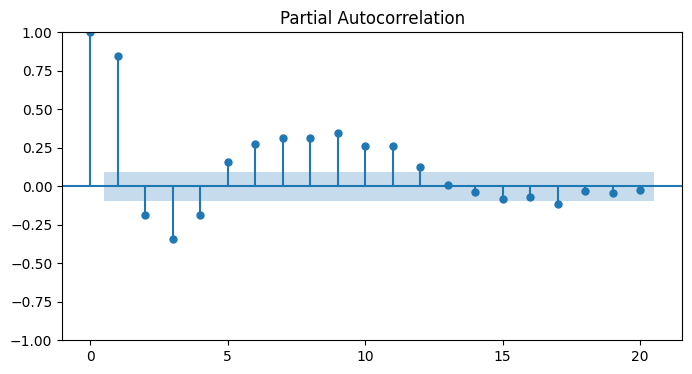

In [ ]:
plot_pacf(df['Value'], lags=20)
plt.show()

Na grafu vidimo da lag od 1 ima direktnu korelaciju, znaci da bi nam lag od 1 mogao doprineti u poboljsanju modela. Isto vazi i za lagove 2-12 ali u manjoj meri.

### Analiza sa ACF i PACF za odredjivanje parametara p i q

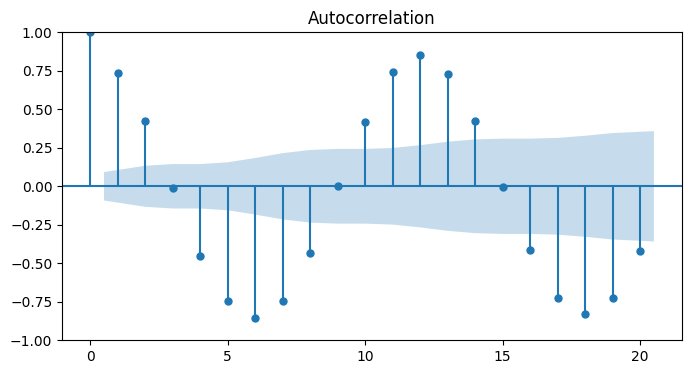

In [ ]:
plot_acf(df['stacionarni'].dropna(), lags=20)
plt.show()

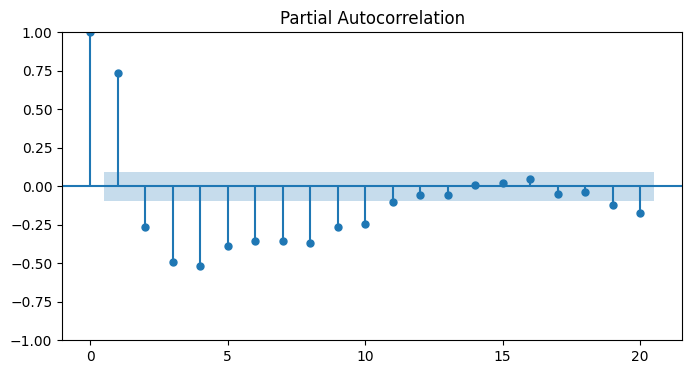

In [ ]:
plot_pacf(df['stacionarni'].dropna(), lags=20, method='ols')
plt.show()

Vrednost za p biramo sa dolnjeg grafa, vidimo da su znacajne vrednosti 1-9 za metodu ywm dok je za ols metodu to opseg 1-11.
Time imam opseg za p: 9 - 11, ako primenim i rezultat ljung-box testa dobijam da je onda opseg za p: 9,10.
Vrednost za q nam dolazi od grafa iznad, znacajna vrednost nam je 2, imamo znacajan pad posle njega.

### Treniranje modela ARMA

In [ ]:

ar_model = ARIMA(df['stacionarni'], order=(9, 0, 2)).fit()
#analizom AIC, BIC i p vrednosti parametara, zkljucujem da su 9,0,2 najbolji paramteri za moj model


In [ ]:
y_test_pred = ar_model.predict(start=df_test.index[0], end=df_test.index[-1])

y_test_pred += stl_test.trend


In [ ]:

mae = mean_absolute_error
actual = df_test['Value']

print(f'{mae(actual, y_test_pred)=:.2f}')

mae(actual, y_test_pred)=3.62
